# 06 Preverjanje učinka ukrepa

**Namen:** preveriti učinek ukrepa s podatki, ne z občutkom. **Ciljna skupina:** odločevalci in mestni načrtovalci.

Težava: če primerjamo koncentracije pred ukrepom in po njem, večino razlike pogosto naredi vreme (ena zima z več inverzije ali manj vetra), ne ukrep. Zato uporabimo **meteorološko normalizacijo**: model iz vremena napove, kakšna bi bila koncentracija ob običajnih emisijah; razlika med izmerjenim in napovedanim (ostanek) je del, ki ga vreme ne pojasni, in v njem iščemo učinek ukrepa.

| Vhod | Vrsta | Datoteka |
|---|---|---|
| dnevni NO2 Bežigrad 2013–2025 | **meritev** (validirano) | `01_meritve/eea_si_validirano_urno_*.csv` |
| dnevni PM10 Bežigrad 2016–2026 | **meritev** | `01_meritve/arso_lj_pm_urno_*.csv` |
| vreme: veter, mejna plast, T, padavine, vlaga, sevanje | **model** (ERA5) | `03_vreme_inverzija/era5_openmeteo_urno_*.csv` |
| inverzija Bežigrad–Pasja ravan | **meritev** | `03_vreme_inverzija/inverzija_urno_*.csv` |

Opomba: validirani NO2 za prometno postajo Celovška je v EEA šele od 2021, zato naravni poskus iz leta 2020 pokažemo na Bežigradu (mestno ozadje, še vedno pod vplivom prometa).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

# NO2 Bežigrad (EEA, validirano, urno -> dnevno)
no2 = pd.concat([pd.read_csv(P / "01_meritve" / f, usecols=["time_utc", "station_code", "pollutant", "aggregation", "value"])
                 for f in ("eea_si_validirano_urno_2013_2019.csv.gz", "eea_si_validirano_urno_2020_2025.csv.gz")])
no2 = no2[(no2.station_code == "SI0003A") & (no2.pollutant == "NO2") & (no2.aggregation == "hour")]
no2["time_utc"] = pd.to_datetime(no2.time_utc, utc=True)
no2_d = dnevno(no2[["time_utc", "value"]].rename(columns={"value": "no2"}))

# PM10 Bežigrad (ARSO, urno -> dnevno)
pm_d = dnevno(nalozi_arso(["E403"]).drop(columns="station_code"))

# vreme (ERA5, model) in inverzija (meritev) -> dnevne značilke
era = nalozi_era5("E403")
inv = nalozi_inverzijo()[["time_utc", "inv_pasja_ravan", "dt_bezigrad_pasja_ravan"]]
w = era.merge(inv, on="time_utc", how="left").set_index("time_utc")
g = w.groupby(w.index.floor("D"))
vreme = pd.DataFrame({
    "veter": g.wind_speed_10m.mean(), "veter_max": g.wind_speed_10m.max(),
    "blh": g.boundary_layer_height.mean(), "blh_min": g.boundary_layer_height.min(),
    "temp": g.temperature_2m.mean(), "padavine": g.precipitation.sum(), "vlaga": g.relative_humidity_2m.mean(),
    "sevanje": g.shortwave_radiation.sum(), "oblacnost": g.cloud_cover.mean(),
    "inv_delez": g.inv_pasja_ravan.mean(), "dt_hrib": g.dt_bezigrad_pasja_ravan.mean(),
}).reset_index().rename(columns={"time_utc": "dan"})
vreme["dan_v_tednu"] = vreme.dan.dt.dayofweek
vreme["mesec"] = vreme.dan.dt.month
vreme["doy_sin"] = np.sin(2 * np.pi * vreme.dan.dt.dayofyear / 365.25)
vreme["doy_cos"] = np.cos(2 * np.pi * vreme.dan.dt.dayofyear / 365.25)
vreme["leto"] = vreme.dan.dt.year + vreme.dan.dt.dayofyear / 365.25   # počasen trend emisij
ZNACILKE = ["veter", "veter_max", "blh", "blh_min", "temp", "padavine", "vlaga", "sevanje", "oblacnost", "inv_delez", "dt_hrib", "dan_v_tednu", "mesec", "doy_sin", "doy_cos", "leto"]
print(f"NO2 dnevno: {no2_d.no2.notna().sum()} dni ({no2_d.dan.min():%Y} – {no2_d.dan.max():%Y}); PM10 dnevno: {pm_d.pm10.notna().sum()} dni; vreme: {len(vreme)} dni")

NO2 dnevno: 4664 dni (2013 – 2025); PM10 dnevno: 3928 dni; vreme: 3969 dni


## 1. Metoda: meteorološka normalizacija

1. Na dnevih **zunaj** obdobja, ki ga ocenjujemo, naučimo model (gradient boosting) `koncentracija = f(vreme, dan v tednu, letni čas)`.
2. Model napove koncentracijo za vse dni, tudi za obdobje ukrepa: to je "pričakovano ob običajnih emisijah".
3. Ostanek = izmerjeno − napovedano. Če je v obdobju ukrepa ostanek sistematično negativen, je to učinek, ki ga vreme ne pojasni.
4. Negotovost: bootstrap po dnevih (ponovno vzorčenje dni v oknu) da 95-odstotni interval.

Dan v tednu je v modelu, ker so emisije prometa ob vikendih drugačne; letni čas zato, da model loči kurilno sezono; leto (zvezno) zato, da počasen trend emisij ne izgleda kot učinek ukrepa. Model se uči na dnevih brez ukrepa, zato učinka ukrepa ne "pojé". Gradient boosting prenese manjkajoče vrednosti (ERA5 nima višine mejne plasti za prvo polovico 2024).

In [2]:
def normaliziraj(y, vreme=vreme, izloci=(None, None), seed=0, znacilke=None):
    """y: DataFrame z 'dan' in enim ciljnim stolpcem. izloci: (od, do) dni, ki jih pri učenju izpustimo (obdobje ukrepa).
    Vrne DataFrame z dan, izmerjeno, napovedano, ostanek, in R² modela na učnih dneh."""
    znacilke = znacilke or ZNACILKE
    cilj = [c for c in y.columns if c != "dan"][0]
    d = y.merge(vreme, on="dan", how="inner").dropna(subset=[cilj])   # manjkajoče značilke (npr. BLH 2024) model prenese
    ucni = np.ones(len(d), bool)
    if izloci[0] is not None:
        ucni &= ~((d.dan >= pd.Timestamp(izloci[0], tz="UTC")) & (d.dan <= pd.Timestamp(izloci[1], tz="UTC")))
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, random_state=seed)
    m.fit(d.loc[ucni, znacilke], d.loc[ucni, cilj])
    d["napovedano"] = m.predict(d[znacilke])
    d["ostanek"] = d[cilj] - d["napovedano"]
    r2 = 1 - ((d.loc[ucni, cilj] - d.loc[ucni, "napovedano"]) ** 2).sum() / ((d.loc[ucni, cilj] - d.loc[ucni, cilj].mean()) ** 2).sum()
    return d[["dan", cilj, "napovedano", "ostanek"]].rename(columns={cilj: "izmerjeno"}), r2, m

def bootstrap_sprememba(okno, n=500, seed=0):
    """Relativna sprememba izmerjeno/napovedano − 1 v oknu z 95 % intervalom (bootstrap po dnevih)."""
    rng = np.random.default_rng(seed)
    obs, pred = okno.izmerjeno.values, okno.napovedano.values
    toc = obs.mean() / pred.mean() - 1
    b = [(lambda i: obs[i].mean() / pred[i].mean() - 1)(rng.integers(0, len(obs), len(obs))) for _ in range(n)]
    return toc, np.percentile(b, 2.5), np.percentile(b, 97.5)

## 2. Naravni poskus: zaprtje spomladi 2020

Med 16. 3. in 30. 4. 2020 je bil promet v Ljubljani močno zmanjšan. To je najboljši "ukrep", ki ga imamo v podatkih. Surova primerjava: povprečje v oknu 2020 proti istemu oknu 2017–2019. Normalizirana: izmerjeno proti napovedanemu iz vremena (model naučen brez leta 2020).

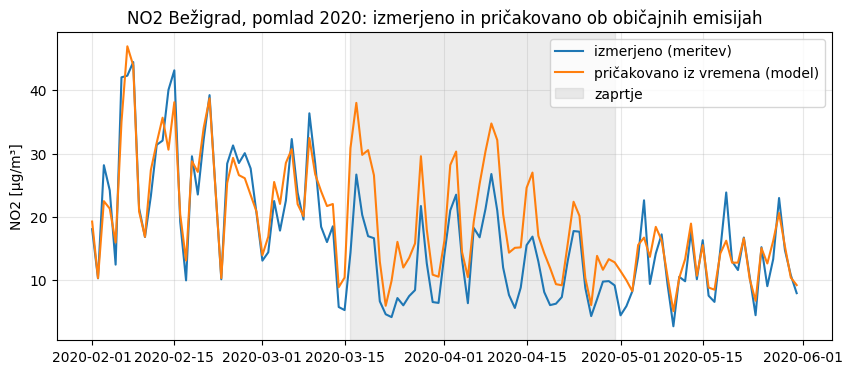

,NO2 Bežigrad,PM10 Bežigrad
r2_modela,0.94,0.88
povp_2020,12.4,21.9
povp_2017_19,25.9,23.0
surova_sprememba,-52%,-5%
napovedano_2020,18.6,18.6
normalizirana_sprememba,-33%,+18%
interval_95,-37% … -30%,+9% … +26%
dni,46,43


In [3]:
OD, DO = "2020-03-16", "2020-04-30"
rez = {}
for ime, y in [("NO2 Bežigrad", no2_d[["dan", "no2"]]), ("PM10 Bežigrad", pm_d[["dan", "pm10"]])]:
    d, r2, _ = normaliziraj(y, izloci=(OD, DO))
    okno = d[(d.dan >= pd.Timestamp(OD, tz="UTC")) & (d.dan <= pd.Timestamp(DO, tz="UTC"))]
    ref = d[d.dan.dt.year.between(2017, 2019) & ((d.dan.dt.month == 3) & (d.dan.dt.day >= 16) | (d.dan.dt.month == 4))]
    surovo = okno.izmerjeno.mean() / ref.izmerjeno.mean() - 1
    toc, lo, hi = bootstrap_sprememba(okno)
    rez[ime] = dict(r2_modela=round(r2, 2), povp_2020=round(okno.izmerjeno.mean(), 1), povp_2017_19=round(ref.izmerjeno.mean(), 1),
                    surova_sprememba=f"{surovo:+.0%}", napovedano_2020=round(okno.napovedano.mean(), 1),
                    normalizirana_sprememba=f"{toc:+.0%}", interval_95=f"{lo:+.0%} … {hi:+.0%}", dni=len(okno))
    if ime.startswith("NO2"):
        fig, ax = plt.subplots(figsize=(10, 4))
        s = d[(d.dan >= "2020-02-01") & (d.dan <= "2020-05-31")]
        ax.plot(s.dan, s.izmerjeno, label="izmerjeno (meritev)"); ax.plot(s.dan, s.napovedano, label="pričakovano iz vremena (model)")
        ax.axvspan(pd.Timestamp(OD, tz="UTC"), pd.Timestamp(DO, tz="UTC"), color="gray", alpha=.15, label="zaprtje")
        ax.set(title="NO2 Bežigrad, pomlad 2020: izmerjeno in pričakovano ob običajnih emisijah", ylabel="NO2 [µg/m³]"); ax.legend(); ax.grid(alpha=.3); plt.show()
pd.DataFrame(rez)

Branje: pri NO2 je normalizirana sprememba tisto, kar je naredil ukrep (manj prometa), pri PM10 pa majhna ali nikakršna, ker PM10 spomladi ne prihaja predvsem iz prometa. Interval pove, ali je učinek razločen od naključnega nihanja. Surova sprememba brez normalizacije bi lahko bila večja ali manjša, odvisno od tega, kakšna je bila pomlad.

## 3. Trend 2016–2026: koliko je vreme, koliko emisije

Zimska povprečja PM10 na Bežigradu nihajo iz leta v leto. Model, naučen na vseh dnevih **samo iz vremena in letnega časa (brez leta)**, pove, kakšne bi bile zime ob povprečnem vremenu: normalizirano zimsko povprečje = skupno povprečje + povprečni ostanek zime. Kar ostane, je sprememba emisij (ali česa drugega, kar ni vreme).

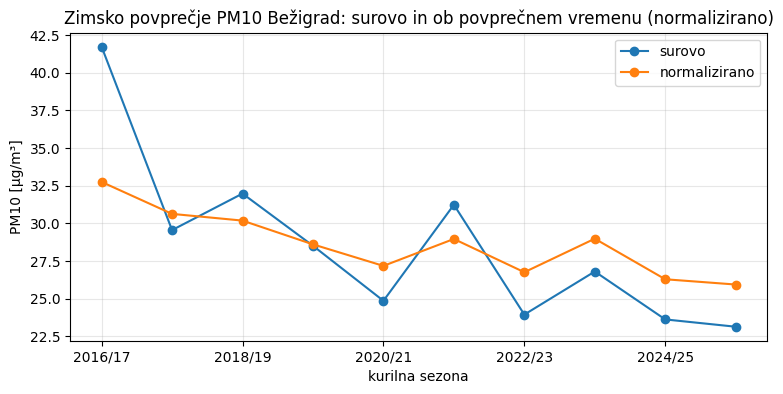

         surovo  ostanek  dni  normalizirano
sezona                                      
2016/17    41.7      4.1  149           32.7
2017/18    29.5      2.0  151           30.6
2018/19    32.0      1.6  149           30.2
2019/20    28.5     -0.0  149           28.6
2020/21    24.8     -1.4  150           27.2
2021/22    31.2      0.3  151           29.0
2022/23    23.9     -1.9  151           26.7
2023/24    26.8      0.4  142           29.0
2024/25    23.6     -2.3  151           26.3
2025/26    23.1     -2.7  151           25.9

R² modela (dnevni PM10 iz vremena): 0.84
trend surovo: -1.47 µg/m³ na zimo; normalizirano (emisije): -0.62 µg/m³ na zimo; delež medletne variance, ki jo pojasni vreme: 85%


In [4]:
BREZ_LETA = [z for z in ZNACILKE if z != "leto"]            # tu leta ne sme biti v modelu, sicer "pojé" trend emisij
d, r2, model = normaliziraj(pm_d[["dan", "pm10"]], znacilke=BREZ_LETA)
d["sezona"] = sezona(d.dan)
z = d[d.dan.dt.month.isin(ZIMSKI_MESECI)]
t = z.groupby("sezona").agg(surovo=("izmerjeno", "mean"), ostanek=("ostanek", "mean"), dni=("izmerjeno", "size"))
t = t[t.dni >= 100]
t["normalizirano"] = z.izmerjeno.mean() + t.ostanek
x = np.arange(len(t))
k_sur = np.polyfit(x, t.surovo, 1)[0]; k_nor = np.polyfit(x, t.normalizirano, 1)[0]
ax = t[["surovo", "normalizirano"]].plot(marker="o", figsize=(9, 4))
ax.set(title="Zimsko povprečje PM10 Bežigrad: surovo in ob povprečnem vremenu (normalizirano)", ylabel="PM10 [µg/m³]", xlabel="kurilna sezona"); ax.grid(alpha=.3); plt.show()
print(t.round(1).to_string())
print(f"\nR² modela (dnevni PM10 iz vremena): {r2:.2f}")
print(f"trend surovo: {k_sur:+.2f} µg/m³ na zimo; normalizirano (emisije): {k_nor:+.2f} µg/m³ na zimo; "
      f"delež medletne variance, ki jo pojasni vreme: {1 - t.normalizirano.var() / t.surovo.var():.0%}")

## 4. Predloga za vaš ukrep

Funkcija `ucinek` združi vse zgoraj: podate dnevno vrsto (katerakoli postaja in onesnaževalo iz paketa ali vaših podatkov), začetek in konec obdobja ukrepa; dobite surovo in normalizirano spremembo z intervalom in graf. Primer spodaj je namišljen (ni bilo ukrepa), zato pričakujemo spremembo blizu nič: tako preverite, da metoda ne "najde" učinka tam, kjer ga ni.

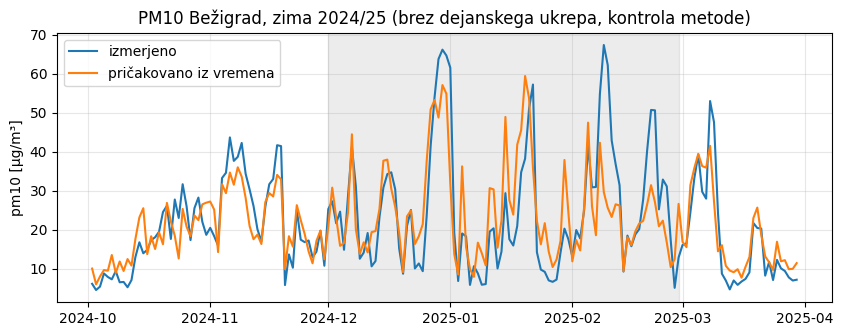

{'dni': 90,
 'r2_modela': np.float64(0.88),
 'surova_sprememba': '-14%',
 'normalizirana_sprememba': '+1%',
 'interval_95': '-8% … +9%'}

In [5]:
def ucinek(y, zacetek, konec, ref_leta=None, naslov=""):
    d, r2, _ = normaliziraj(y, izloci=(zacetek, konec))
    okno = d[(d.dan >= pd.Timestamp(zacetek, tz="UTC")) & (d.dan <= pd.Timestamp(konec, tz="UTC"))]
    toc, lo, hi = bootstrap_sprememba(okno)
    cilj = [c for c in y.columns if c != "dan"][0]
    if ref_leta:
        z0, k0 = pd.Timestamp(zacetek, tz="UTC"), pd.Timestamp(konec, tz="UTC")
        maska = np.zeros(len(d), bool)
        for r in ref_leta:                                   # isto koledarsko okno v referenčnih letih
            k = r - z0.year
            maska |= ((d.dan >= z0 + pd.DateOffset(years=k)) & (d.dan <= k0 + pd.DateOffset(years=k))).values
        surovo = okno.izmerjeno.mean() / d[maska].izmerjeno.mean() - 1
    else:
        surovo = np.nan
    fig, ax = plt.subplots(figsize=(10, 3.5))
    s = d[(d.dan >= pd.Timestamp(zacetek, tz="UTC") - pd.Timedelta(days=60)) & (d.dan <= pd.Timestamp(konec, tz="UTC") + pd.Timedelta(days=30))]
    ax.plot(s.dan, s.izmerjeno, label="izmerjeno"); ax.plot(s.dan, s.napovedano, label="pričakovano iz vremena")
    ax.axvspan(pd.Timestamp(zacetek, tz="UTC"), pd.Timestamp(konec, tz="UTC"), color="gray", alpha=.15)
    ax.set(title=naslov or f"{cilj}: {zacetek} – {konec}", ylabel=f"{cilj} [µg/m³]"); ax.legend(); ax.grid(alpha=.3); plt.show()
    return dict(dni=len(okno), r2_modela=round(r2, 2), surova_sprememba=None if np.isnan(surovo) else f"{surovo:+.0%}",
                normalizirana_sprememba=f"{toc:+.0%}", interval_95=f"{lo:+.0%} … {hi:+.0%}")

# namišljen "ukrep" 1. 12. 2024 – 28. 2. 2025 na PM10 Bežigrad (v resnici ga ni bilo)
ucinek(pm_d[["dan", "pm10"]], "2024-12-01", "2025-02-28", ref_leta=[2021, 2022, 2023], naslov="PM10 Bežigrad, zima 2024/25 (brez dejanskega ukrepa, kontrola metode)")

## Omejitve, ki jih povejte v pitchu

- **Ena postaja, brez kontrolne skupine.** Boljši načrt: primerjava z drugo postajo, kjer ukrepa ni bilo (razlika v razlikah), na primer Celovška proti Bežigradu.
- **Vreme je iz reanalize (model)**, ne iz meritev; za lokalne učinke (en zaprt odsek ceste) je prostorsko pregrobo.
- **Časovna avtokorelacija**: dnevi niso neodvisni, zato je bootstrap po dnevih optimističen; za resno oceno uporabite bloke (tedne).
- **Kratki ukrepi** (nekaj dni) utonejo v šumu; metoda potrebuje vsaj nekaj tednov.
- Model se uči na preteklih emisijah; postopne spremembe (menjava peči skozi leta) so videti kot trend ostankov, ne kot skok.

## Kaj lahko ekipa iz tega naredi

1. **Orodje za občino**: naloži dnevne vrste s postaj, označi obdobje ukrepa, dobi učinek z intervalom in graf, ki ga razume nestrokovnjak.
2. **Razlika v razlikah** s Celovško kot "ukrepano" in Bežigradom kot kontrolo za prometne ukrepe (NO2 Celovška je v EEA od 2021, v ARSO XML v živo pa vsak dan).
3. **Spremljanje v živo**: ostanek dneva proti pričakovanju iz napovedi vremena kot "indeks emisij danes".
4. **Scenariji vnaprej**: isti model z vremensko klimatologijo pove, koliko dni nad mejo bi bilo ob x % nižjih emisijah (glej zvezek 07).